# EasyOCR — Color Filter Comparison

This notebook evaluates how different **image preprocessing / color filters** affect EasyOCR text detection quality, with a focus on **license plate recognition**.

Each filter transforms the input image before it is passed to the OCR engine. The goal is to identify which preprocessing pipeline yields the highest detection confidence and the most complete text recovery.

Filters tested:
- Original (no preprocessing)
- Grayscale
- CLAHE-enhanced grayscale
- Inverted image
- HSV Value channel
- LAB L-channel
- Otsu binary threshold
- Adaptive threshold
- Yellow/white color mask (license-plate targeted)


## 1 · Imports & Setup

We import:
- `easyocr` — OCR engine
- `cv2` — image loading, drawing, and filter operations
- `matplotlib` — inline display and bar charts
- `numpy` — array manipulation
- `pandas` — confidence score summary table
- `glob / os / tempfile` — file discovery and temp storage


In [37]:
import os
import glob
import tempfile
import cv2
import numpy as np
import easyocr
import matplotlib.pyplot as plt
import pandas as pd

# ── Image folder ──────────────────────────────────────────────────────────────
IMAGE_DIR = "images/close-up"

image_paths = (
    glob.glob(os.path.join(IMAGE_DIR, "*.jpg")) +
    glob.glob(os.path.join(IMAGE_DIR, "*.jpeg")) +
    glob.glob(os.path.join(IMAGE_DIR, "*.png"))
)
# Exclude previously saved annotated files
image_paths = [p for p in image_paths if not os.path.basename(p).startswith("annotated_")]

print(f"Found {len(image_paths)} image(s): {[os.path.basename(p) for p in image_paths]}")

# ── Initialise EasyOCR reader once ────────────────────────────────────────────
reader = easyocr.Reader(['en', 'nl'], gpu=False)
print("EasyOCR reader ready.")


Using CPU. Note: This module is much faster with a GPU.


Found 5 image(s): ['26681596558_dfd890198e_b.jpg', 'nl_v-75-fxj_close.jpg', 'R (1).jpg', 'R.jpg', 'sealseuropeanlicenseplate.jpg']
EasyOCR reader ready.


## 2 · Image Loading & Helper Functions

- `annotate_image()` — draws green bounding polygons and confidence labels on a BGR image copy
- `show_images()` — renders a `{label: bgr_image}` dict as a matplotlib grid


In [38]:
def annotate_image(image_bgr, ocr_results, font_scale=0.6, thickness=2, min_confidence=0.3):
    """Draw bounding polygons and text labels onto a copy of image_bgr.
    Only detections with confidence >= min_confidence are drawn.
    """
    out = image_bgr.copy()
    for (bbox, text, confidence) in ocr_results:
        if confidence < min_confidence:
            continue
        pts = np.array([[int(x), int(y)] for x, y in bbox])
        cv2.polylines(out, [pts], isClosed=True, color=(0, 255, 0), thickness=thickness)
        label = f"{text} ({confidence:.2f})"
        top_left = pts[0]
        (tw, th), bl = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, thickness)
        lx, ly = top_left[0], max(top_left[1] - 8, th + 8)
        cv2.rectangle(out, (lx, ly - th - bl - 4), (lx + tw + 6, ly + bl), (0, 255, 0), cv2.FILLED)
        cv2.putText(out, label, (lx + 3, ly - bl), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness)
    return out


def show_images(annotated_dict, title="Results", max_cols=3):
    """
    annotated_dict: {label_string: annotated_bgr_image}
    Displays images in a grid with at most max_cols per row.
    """
    items = list(annotated_dict.items())
    n = len(items)
    if n == 0:
        print("No images to display.")
        return
    cols = min(n, max_cols)
    rows = -(-n // cols)  # ceiling division

    fig, axes = plt.subplots(rows, cols, figsize=(9 * cols, 7 * rows))

    # Normalise axes to always be a flat list
    if rows == 1 and cols == 1:
        axes = [axes]
    elif rows == 1 or cols == 1:
        axes = list(np.array(axes).flatten())
    else:
        axes = [ax for row in axes for ax in row]

    fig.suptitle(title, fontsize=14, fontweight="bold")

    for ax, (label, img_bgr) in zip(axes, items):
        ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        ax.set_title(label, fontsize=9, wrap=True)
        ax.axis("off")

    for ax in axes[n:]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()


## 3 · Color Filter Definitions

Each filter is a function `(bgr_image) → bgr_image`.  
Grayscale and single-channel outputs are converted back to 3-channel BGR so EasyOCR can process them uniformly.

| Filter | What it does |
|--------|-------------|
| **Original** | No change |
| **Grayscale** | Removes colour — reduces noise from colour channels |
| **CLAHE** | Contrast Limited Adaptive Histogram Equalisation — boosts local contrast |
| **Inverted** | Flips pixel values — useful for white-on-dark plates |
| **HSV Value** | Isolates brightness regardless of colour |
| **LAB L-channel** | Perceptual lightness channel — separates luminance from colour |
| **Otsu Threshold** | Global binary threshold chosen automatically |
| **Adaptive Threshold** | Local binary threshold — robust to uneven lighting |
| **Yellow/White Mask** | Keeps only yellow and white pixels (typical plate colors) |


In [39]:
def filter_original(img):
    return img.copy()


def filter_grayscale(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)


def filter_clahe(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    return cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR)


def filter_inverted(img):
    return cv2.bitwise_not(img)


def filter_hsv_value(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    v_channel = hsv[:, :, 2]
    return cv2.cvtColor(v_channel, cv2.COLOR_GRAY2BGR)


def filter_lab_l(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l_channel = lab[:, :, 0]
    return cv2.cvtColor(l_channel, cv2.COLOR_GRAY2BGR)


def filter_otsu(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return cv2.cvtColor(thresh, cv2.COLOR_GRAY2BGR)


def filter_adaptive(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    adaptive = cv2.adaptiveThreshold(
        gray, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        blockSize=15,
        C=8
    )
    return cv2.cvtColor(adaptive, cv2.COLOR_GRAY2BGR)


def filter_plate_mask(img):
    """Keep only yellow and white pixels — common license plate colors."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # White: low saturation, high value
    white_lower = np.array([0,   0,  180], dtype=np.uint8)
    white_upper = np.array([180, 55, 255], dtype=np.uint8)

    # Yellow: hue ~20-35
    yellow_lower = np.array([18,  80, 100], dtype=np.uint8)
    yellow_upper = np.array([35, 255, 255], dtype=np.uint8)

    mask_white  = cv2.inRange(hsv, white_lower,  white_upper)
    mask_yellow = cv2.inRange(hsv, yellow_lower, yellow_upper)
    combined    = cv2.bitwise_or(mask_white, mask_yellow)

    result = cv2.bitwise_and(img, img, mask=combined)
    return result


# ── Ordered filter registry ───────────────────────────────────────────────────
FILTERS = {
    "Original":          filter_original,
    "Grayscale":         filter_grayscale,
    "CLAHE":             filter_clahe,
    "Inverted":          filter_inverted,
    "HSV Value":         filter_hsv_value,
    "LAB L-channel":     filter_lab_l,
    "Otsu Threshold":    filter_otsu,
    "Adaptive Threshold": filter_adaptive,
    "Yellow/White Mask": filter_plate_mask,
}

print(f"Defined {len(FILTERS)} filter(s): {list(FILTERS.keys())}")


Defined 9 filter(s): ['Original', 'Grayscale', 'CLAHE', 'Inverted', 'HSV Value', 'LAB L-channel', 'Otsu Threshold', 'Adaptive Threshold', 'Yellow/White Mask']


## 4 · Apply Filters & Run OCR

For each image and each filter:
1. Apply the preprocessing function to get a filtered BGR image
2. Save it to a temporary file (EasyOCR works best reading from a file path)
3. Run `reader.readtext()` and store the results
4. Print detected texts with confidence scores


In [40]:
# ocr_data[image_path][filter_label] = list of (bbox, text, confidence)
ocr_data = {}
# filtered_images[image_path][filter_label] = bgr_image after filter
filtered_images = {}

OCR_PARAMS = dict(
    text_threshold=0.7,
    low_text=0.4,
    mag_ratio=1.0,
)

for image_path in image_paths:
    image = cv2.imread(image_path)
    if image is None:
        print(f"[SKIP] Cannot read {image_path}")
        continue

    name = os.path.basename(image_path)
    print(f"\n{'='*60}")
    print(f"Image: {name}")
    print(f"{'='*60}")

    ocr_data[image_path] = {}
    filtered_images[image_path] = {}

    for filter_label, filter_fn in FILTERS.items():
        filtered = filter_fn(image)
        filtered_images[image_path][filter_label] = filtered

        # Write to a temp PNG so EasyOCR reads a clean file
        with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as tmp:
            tmp_path = tmp.name
        cv2.imwrite(tmp_path, filtered)

        results = reader.readtext(tmp_path, **OCR_PARAMS)
        os.remove(tmp_path)

        ocr_data[image_path][filter_label] = results

        texts = [(t, f"{c:.2f}") for _, t, c in results]
        print(f"  {filter_label:<22} → {len(results)} region(s)  {texts}")



Image: 26681596558_dfd890198e_b.jpg


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


  Original               → 3 region(s)  [('NL', '1.00'), ('CD-73-05', '1.00'), ('6095425015', '0.71')]


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


  Grayscale              → 3 region(s)  [('NL', '1.00'), ('CD-73-05', '1.00'), ('6095+25015', '0.69')]


...

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


  Otsu Threshold         → 2 region(s)  [('NU', '0.26'), ('1685', '1.00')]


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


  Adaptive Threshold     → 3 region(s)  [('S', '0.33'), ('NU ~', '0.22'), ('1685', '1.00')]
  Yellow/White Mask      → 1 region(s)  [('ENTG85|', '0.06')]


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


## 5 · Side-by-Side Visual Comparison

Each image is shown once per filter with annotated bounding boxes overlaid, so you can compare both the visual appearance of each filter **and** how the OCR boxes change.


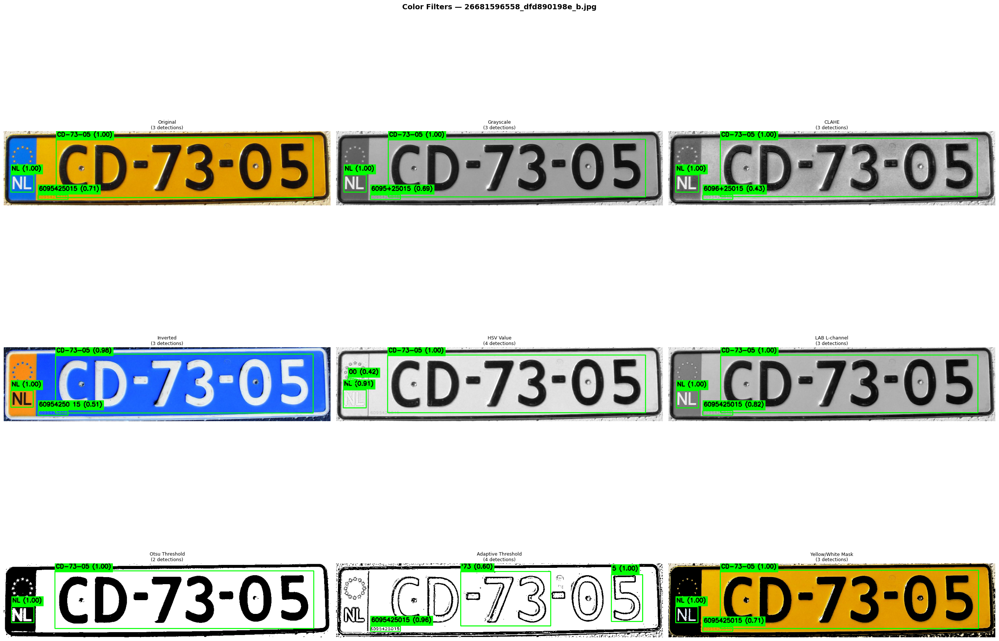

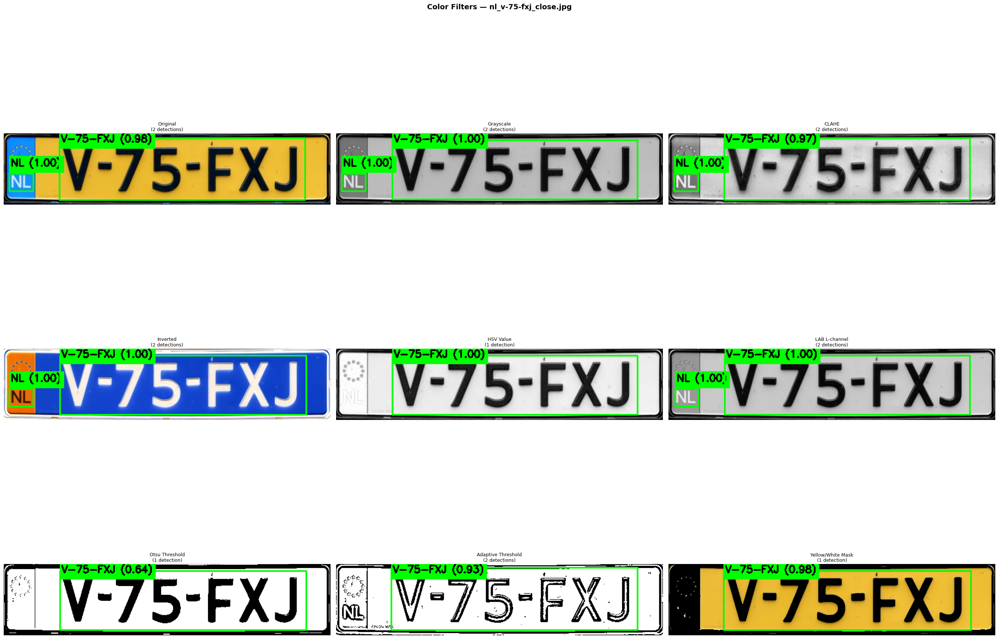

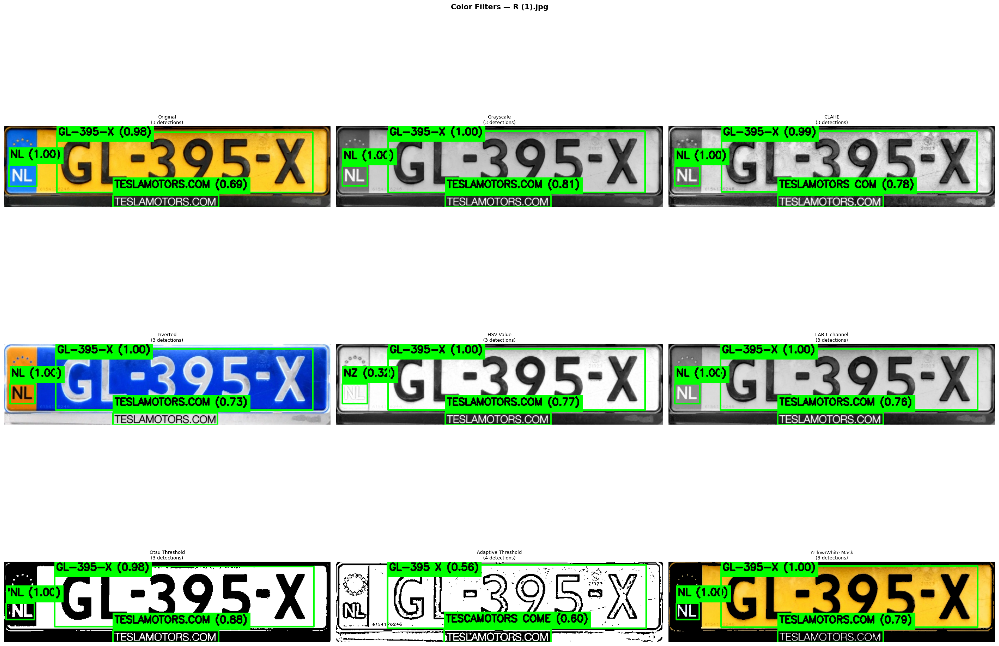

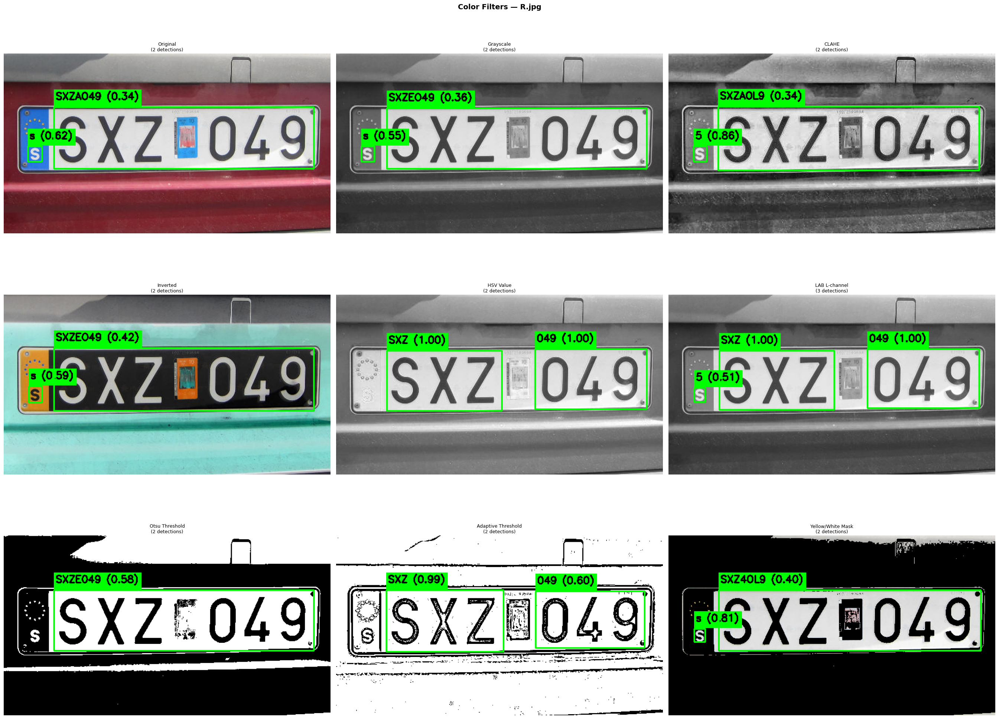

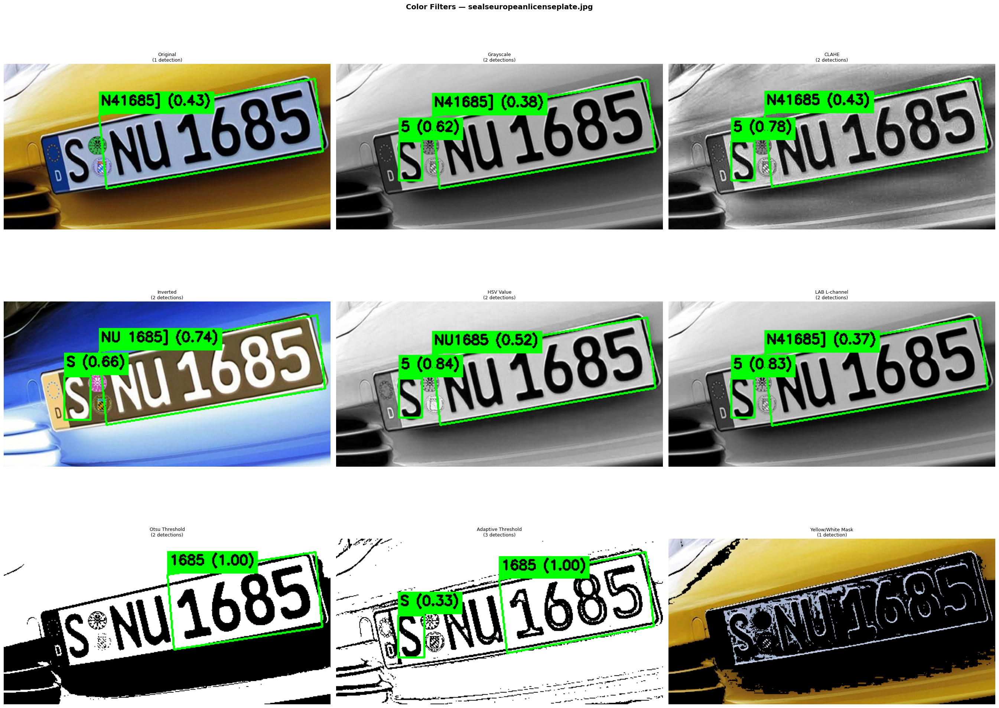

In [41]:
for image_path in image_paths:
    if image_path not in ocr_data:
        continue

    name = os.path.basename(image_path)
    variants = {}

    for filter_label in FILTERS:
        filtered_img = filtered_images[image_path][filter_label]
        results      = ocr_data[image_path][filter_label]
        annotated    = annotate_image(filtered_img, results)
        n_det        = len(results)
        variants[f"{filter_label}\n({n_det} detection{'s' if n_det != 1 else ''})"] = annotated

    show_images(variants, title=f"Color Filters — {name}", max_cols=3)


## 6 · Confidence Score Analysis

Build a summary DataFrame per image and visualise:
1. **Mean confidence** per filter (grouped bar chart)
2. **Total detection count** per filter (secondary bar chart)



26681596558_dfd890198e_b.jpg — per-filter summary:
            filter  mean_confidence  detections
          Original         0.903246           3
         Grayscale         0.897452           3
             CLAHE         0.807570           3
          Inverted         0.828595           3
         HSV Value         0.616763           4
     LAB L-channel         0.939715           3
    Otsu Threshold         0.998761           2
Adaptive Threshold         0.690925           4
 Yellow/White Mask         0.903919           3


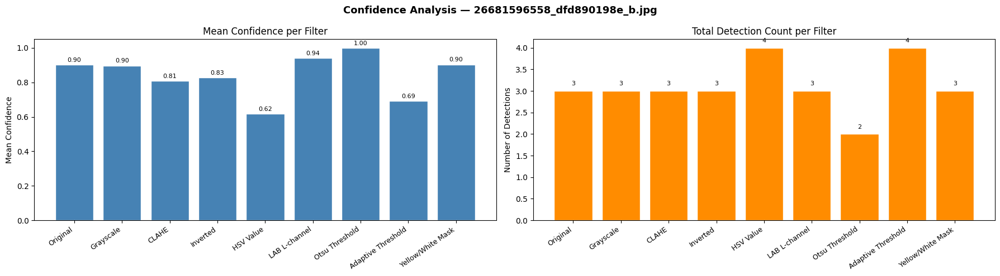


nl_v-75-fxj_close.jpg — per-filter summary:
            filter  mean_confidence  detections
          Original         0.987345           2
         Grayscale         0.997354           2
             CLAHE         0.985137           2
          Inverted         0.998295           2
         HSV Value         0.996759           1
     LAB L-channel         0.997410           2
    Otsu Threshold         0.639542           1
Adaptive Threshold         0.476793           2
 Yellow/White Mask         0.979477           1


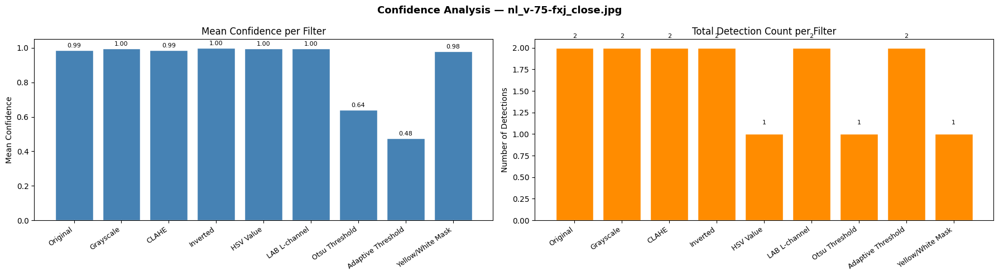


R (1).jpg — per-filter summary:
            filter  mean_confidence  detections
          Original         0.891862           3
         Grayscale         0.934952           3
             CLAHE         0.923117           3
          Inverted         0.908836           3
         HSV Value         0.695499           3
     LAB L-channel         0.919729           3
    Otsu Threshold         0.951461           3
Adaptive Threshold         0.323925           4
 Yellow/White Mask         0.927697           3


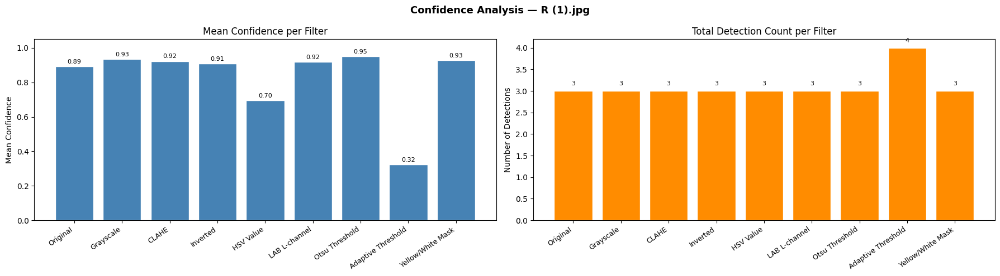


R.jpg — per-filter summary:
            filter  mean_confidence  detections
          Original         0.476836           2
         Grayscale         0.456780           2
             CLAHE         0.599323           2
          Inverted         0.505296           2
         HSV Value         0.998123           2
     LAB L-channel         0.834270           3
    Otsu Threshold         0.367010           2
Adaptive Threshold         0.794695           2
 Yellow/White Mask         0.603340           2


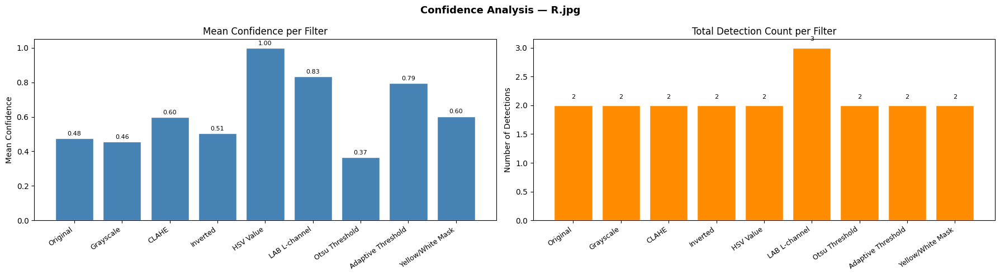


sealseuropeanlicenseplate.jpg — per-filter summary:
            filter  mean_confidence  detections
          Original         0.426186           1
         Grayscale         0.501979           2
             CLAHE         0.602216           2
          Inverted         0.701135           2
         HSV Value         0.683255           2
     LAB L-channel         0.596643           2
    Otsu Threshold         0.630116           2
Adaptive Threshold         0.515102           3
 Yellow/White Mask         0.064598           1


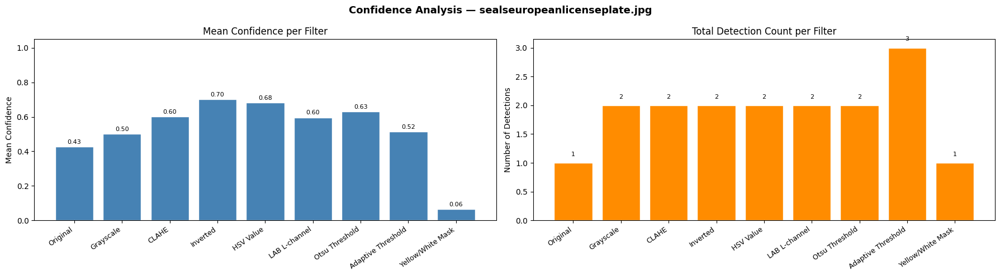

In [42]:
for image_path in image_paths:
    if image_path not in ocr_data:
        continue

    name = os.path.basename(image_path)

    # Build flat records
    records = []
    for filter_label, results in ocr_data[image_path].items():
        for _, text, conf in results:
            records.append({"filter": filter_label, "detected_text": text, "confidence": conf})

    if not records:
        print(f"[{name}] No detections across any filter.")
        continue

    df = pd.DataFrame(records)

    # ── Summary stats ─────────────────────────────────────────────────────────
    summary = (
        df.groupby("filter")
          .agg(mean_confidence=("confidence", "mean"), detections=("confidence", "count"))
          .reindex(list(FILTERS.keys()))   # preserve filter order
          .fillna(0)
          .reset_index()
    )

    print(f"\n{name} — per-filter summary:")
    print(summary.to_string(index=False))

    # ── Bar charts ────────────────────────────────────────────────────────────
    x = range(len(summary))
    labels = summary["filter"].tolist()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))
    fig.suptitle(f"Confidence Analysis — {name}", fontsize=13, fontweight="bold")

    # Mean confidence
    bars1 = ax1.bar(x, summary["mean_confidence"], color="steelblue", edgecolor="white")
    ax1.set_xticks(list(x))
    ax1.set_xticklabels(labels, rotation=35, ha="right", fontsize=9)
    ax1.set_ylabel("Mean Confidence")
    ax1.set_ylim(0, 1.05)
    ax1.set_title("Mean Confidence per Filter")
    for bar, val in zip(bars1, summary["mean_confidence"]):
        if val > 0:
            ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                     f"{val:.2f}", ha="center", va="bottom", fontsize=8)

    # Detection count
    bars2 = ax2.bar(x, summary["detections"], color="darkorange", edgecolor="white")
    ax2.set_xticks(list(x))
    ax2.set_xticklabels(labels, rotation=35, ha="right", fontsize=9)
    ax2.set_ylabel("Number of Detections")
    ax2.set_title("Total Detection Count per Filter")
    for bar, val in zip(bars2, summary["detections"]):
        if val > 0:
            ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
                     str(int(val)), ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.show()


## 7 · Best Filter Summary

Rank filters by mean confidence across all images combined, then re-run OCR with the **top-performing filter** using best-practice parameters tuned for license plates.


Filter ranking by mean confidence (all images combined):

            filter  mean_confidence  total_detections
     LAB L-channel         0.866865                13
          Inverted         0.801812                12
             CLAHE         0.797118                12
          Original         0.794534                11
         Grayscale         0.784120                12
 Yellow/White Mask         0.774561                10
    Otsu Threshold         0.748570                10
         HSV Value         0.742755                12
Adaptive Threshold         0.543179                15

→ Best filter: 'LAB L-channel'  (mean conf = 0.867)

Re-running OCR with best filter + tuned params
Image                               Text                           Confidence
------------------------------------------------------------------------------


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


26681596558_dfd890198e_b.jpg        NL                                   1.00
26681596558_dfd890198e_b.jpg        CD-73-05                             0.68
26681596558_dfd890198e_b.jpg        6095425015                           0.70


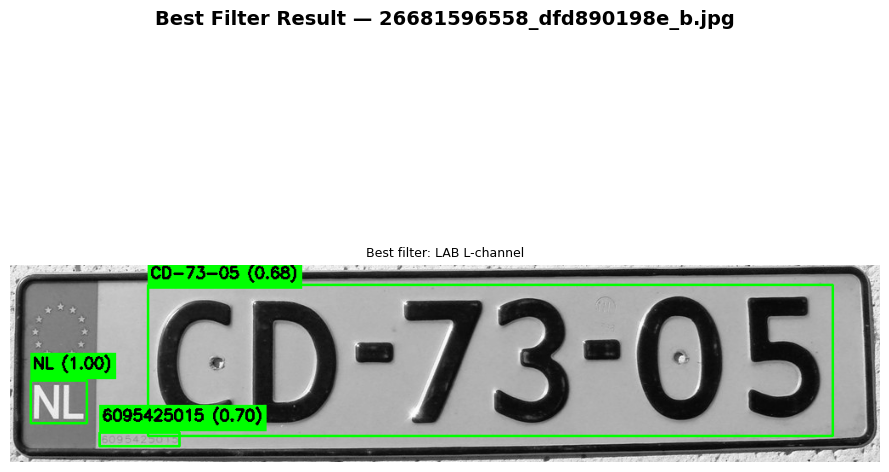

nl_v-75-fxj_close.jpg               NL                                   1.00
nl_v-75-fxj_close.jpg               V-75-FXJ                             0.79


c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


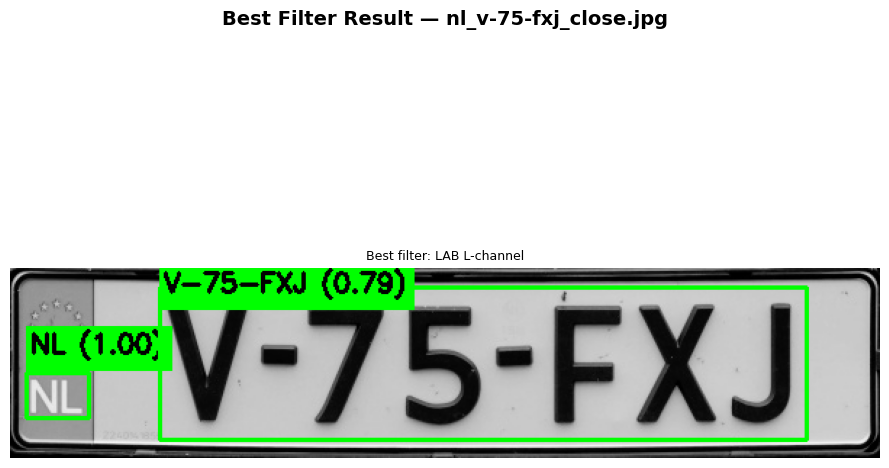

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\easyocr\utils.py:221: RuntimeWarning: overflow encountered in scalar add
  curr.entries[labeling].prTotal += prBlank + prNonBlank
c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\easyocr\utils.py:248: RuntimeWarning: overflow encountered in scalar add
  curr.entries[newLabeling].prNonBlank += prNonBlank
c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\easyocr\utils.py:249: RuntimeWarning: overflow encountered in scalar add
  curr.entries[newLabeling].prTotal += prNonBlank


R (1).jpg                           NL                                   1.00
R (1).jpg                           GL-395-X                             1.00
R (1).jpg                           TESLAMOTORSCOM                       1.00


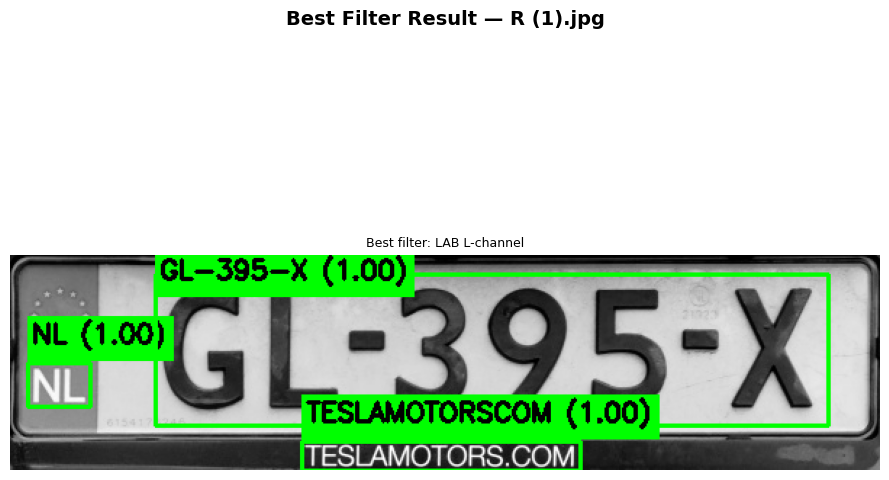

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


R.jpg                               5                                    0.44
R.jpg                               SXZ4O49                              0.51


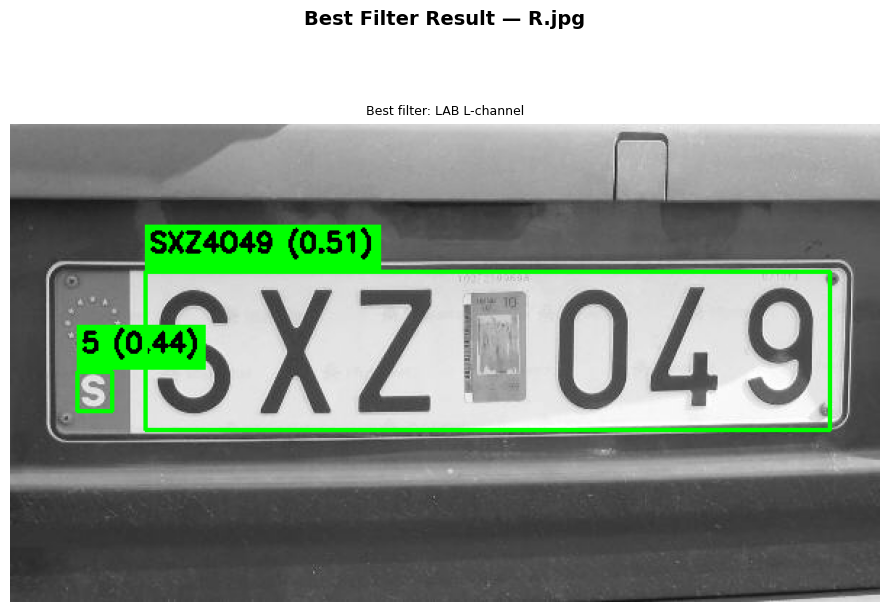

c:\Users\krist\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


sealseuropeanlicenseplate.jpg       S                                    0.98
sealseuropeanlicenseplate.jpg       1685                                 0.97
sealseuropeanlicenseplate.jpg       NU                                   0.91


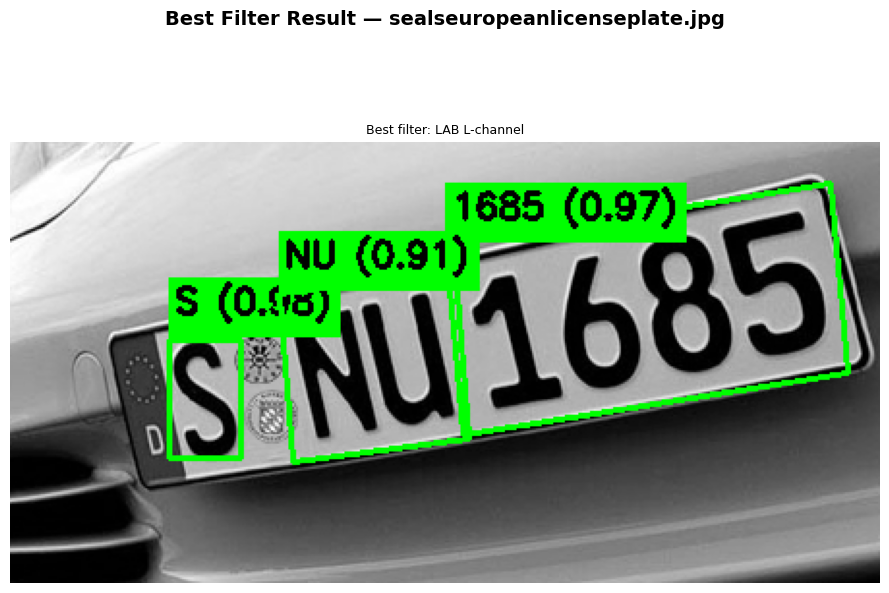

In [43]:
PLATE_CHARS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-"

BEST_OCR_PARAMS = dict(
    text_threshold=0.7,
    low_text=0.4,
    mag_ratio=1.5,
    link_threshold=0.4,
    width_ths=0.7,
    decoder="beamsearch",
    beamWidth=5,
    allowlist=PLATE_CHARS,
    paragraph=False,
)

# ── Aggregate all detections across every image ───────────────────────────────
all_records = []
for image_path, filter_results in ocr_data.items():
    for filter_label, results in filter_results.items():
        for _, text, conf in results:
            all_records.append({"filter": filter_label, "confidence": conf})

if not all_records:
    print("No OCR data available. Run section 4 first.")
else:
    global_df = pd.DataFrame(all_records)
    ranking = (
        global_df.groupby("filter")
                 .agg(mean_confidence=("confidence", "mean"),
                      total_detections=("confidence", "count"))
                 .sort_values("mean_confidence", ascending=False)
                 .reset_index()
    )

    print("Filter ranking by mean confidence (all images combined):\n")
    print(ranking.to_string(index=False))

    best_filter_label = ranking.iloc[0]["filter"]
    best_filter_fn    = FILTERS[best_filter_label]
    print(f"\n→ Best filter: '{best_filter_label}'  "
          f"(mean conf = {ranking.iloc[0]['mean_confidence']:.3f})")

    # ── Re-run with best filter + tuned params ────────────────────────────────
    print("\n" + "="*60)
    print("Re-running OCR with best filter + tuned params")
    print("="*60)
    print(f"{'Image':<35} {'Text':<30} {'Confidence':>10}")
    print("-" * 78)

    for image_path in image_paths:
        image = cv2.imread(image_path)
        if image is None:
            continue

        filtered = best_filter_fn(image)

        with tempfile.NamedTemporaryFile(suffix=".png", delete=False) as tmp:
            tmp_path = tmp.name
        cv2.imwrite(tmp_path, filtered)
        results = reader.readtext(tmp_path, **BEST_OCR_PARAMS)
        os.remove(tmp_path)

        name = os.path.basename(image_path)
        for _, text, conf in results:
            print(f"{name:<35} {text:<30} {conf:>10.2f}")

        annotated = annotate_image(filtered, results)
        show_images(
            {f"Best filter: {best_filter_label}": annotated},
            title=f"Best Filter Result — {name}",
        )
